In [1]:
import numpy as np
import matplotlib.pyplot as plt

testiData = np.zeros((600,3))

testiData[0:100,:] = np.array([1600, 150, 1000])
testiData[100:200,:] = np.array([1500, 1000, 80])
testiData[200:300,:] = np.array([100, 1550, 1000])
testiData[300:400,:] = np.array([1000, 1500, 80])
testiData[400:500,:] = np.array([1000, 150, 1500])
testiData[500:600,:] = np.array([100, 1000, 1700])

testiData += 500*np.random.rand(600,3)

In [30]:
data = np.loadtxt("mittaukset_mysql.csv", delimiter=";", skiprows=1, usecols=(4,5,6), max_rows=600)
print(data)
print(data.shape)

[[1218. 1412. 1581.]
 [1216. 1406. 1589.]
 [1221. 1404. 1585.]
 ...
 [1557. 1461. 1265.]
 [1685. 1516. 1231.]
 [1561. 1547. 1278.]]
(600, 3)


In [26]:
def arvonta(maara,data):
  out = np.zeros((maara,3),dtype=int)
  max = np.max(data)
  min = np.min(data)
  intmin = int(min)
  intmax = int(max)
  for i in range(maara):
    arvottuPiste = np.random.randint(intmin,intmax,3)
    #print("min",intmin,"max",intmax)
    #print("piste",arvottuPiste)
    out[i] = arvottuPiste
    #print(out)
  return out

def etaisyys(point1,point2):
  point2x = int(point2[0])
  point2y = int(point2[1])
  point2z = int(point2[2])
  x_distance = point2x-point1[0]
  y_distance = point2y-point1[1]
  z_distance = point2z-point1[2]
  distance = np.sqrt(x_distance**2 + y_distance**2 + z_distance**2)
  out = int(distance)
  return out

def mittaus(keskipisteet,data):
  rivit = keskipisteet.shape[0]
  dataRivit = data.shape[0]
  #print("dataRivit", dataRivit)
  #print("rivit", rivit)
  #print(keskipisteet[0])
  etaisyydet = np.zeros((dataRivit,rivit))
  for dr in range(dataRivit):
    for r in range(rivit):
      piste = etaisyys(keskipisteet[r],data[dr])
      etaisyydet[dr,r] = piste
  #print(etaisyydet)
  lahimmat = np.argmin(etaisyydet,axis=1)
  #print(lahimmat)
  return lahimmat

def summa(data,lahimmat,keskipisteet):
  rivit = keskipisteet.shape[0]
  dataRivit = data.shape[0]
  summa = np.zeros((rivit,3),dtype=int)
  voittoMaara = np.zeros(rivit,dtype=int)
  for i in range(rivit):
    for d in range(dataRivit):
      if lahimmat[d] == i:
        piste = data[d].astype(int)
        #print(piste)
        summa[i] += piste
        voittoMaara[i] += 1
  #print(summa)
  #print(voittoMaara)
  return summa, voittoMaara

def keskipisteiden_liikutus(voittoMaara,keskipisteet,data,summa):
  rivit = keskipisteet.shape[0]
  vmaara = voittoMaara.shape[0]
  summat = summa.shape[0]
  for vm in range(vmaara):
    #print(voittoMaara[vm])
    v = voittoMaara[vm]
    if v == 0:
      a = arvonta(1,data)
      keskipisteet[vm] = a
    else:
      sx = summa[vm,0]
      sy = summa[vm,1]
      sz = summa[vm,2]
      sx = sx/v
      sy = sy/v
      sz = sz/v
      keskipisteet[vm,0] = sx
      keskipisteet[vm,1] = sy
      keskipisteet[vm,2] = sz
  return keskipisteet

In [29]:
a = arvonta(6,data)
print("alku",a)
while(1):
  m = mittaus(a,data)
  s,v = summa(data,m,a)
  vmaara = v.shape[0]
  for vm in range(vmaara):
    if v[vm] == 0:
      a[vm] = arvonta(1,data)
  m = mittaus(a,data)
  s,v = summa(data,m,a)
  a = keskipisteiden_liikutus(v,a,data,s)
  print("Keskipisteet",a)
  print("voitto määrä",v)
  if np.all(np.array(v) > 0):
      break
print("loppu")


alku [[ 885 1175 1595]
 [1062 1573 1163]
 [1512 1326 1457]
 [1581 1428 1430]
 [1632 1587 1170]
 [1417 1199 1161]]
Keskipisteet [[1167 1258 1502]
 [1221 1564 1474]
 [1409 1301 1523]
 [1643 1508 1447]
 [1554 1528 1245]
 [1507 1300 1242]]
voitto määrä [  1   6 209 318  53  13]
loppu


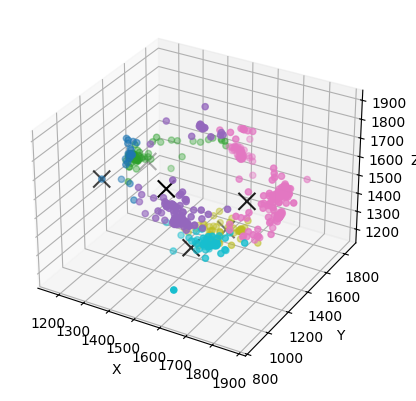

In [38]:
m = mittaus(a, data)

fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")

# Mittauspisteet klusterin mukaan väritettynä
ax.scatter(data[:,0], data[:,1], data[:,2], c=m, cmap="tab10")

# Keskipisteet
ax.scatter(a[:,0], a[:,1], a[:,2], c="black", marker="x", s=150)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

plt.show()

In [39]:
from google.colab import files

arr = a
rows, cols = arr.shape
formatted_rows = [
    "    {" + ", ".join(f"{int(val)}" for val in row) + "}"
    for row in arr
]
c_array_body = ",\n".join(formatted_rows)

header_content = f"""#ifndef keskipisteet_H
#define keskipisteet_H

const int keskipisteet[{rows}][{cols}] = {{
{c_array_body}
}};

#endif // keskipisteet_H
"""

filename = "keskipisteet.h"
with open(filename, "w") as f:
    f.write(header_content)

files.download(filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>